# Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


# Load Clean Dataset

In [2]:
file_path = "data/chicago_crime_cleaned.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully.
Rows: 228595
Columns: 17


# Convert Date again

In [3]:
df["DATE_OF_OCCURRENCE"] = pd.to_datetime(
    df["DATE_OF_OCCURRENCE"],
    errors="coerce"
)

print(df["DATE_OF_OCCURRENCE"].dtype)

datetime64[ns]


# 3.1 — Basic Crime Statistics

#### Overall statistics

In [4]:
print("Total number of crime records:", len(df))
print("Number of columns:", len(df.columns))
print("Number of unique crime types:",
      df["PRIMARY_DESCRIPTION"].nunique())

print("Number of unique secondary crime descriptions:",
      df["SECONDARY_DESCRIPTION"].nunique())

print("Number of unique locations:",
      df["LOCATION_DESCRIPTION"].nunique())

print("Number of unique beats:",
      df["BEAT"].nunique())

print("Number of unique wards:",
      df["WARD"].nunique())

Total number of crime records: 228595
Number of columns: 17
Number of unique crime types: 31
Number of unique secondary crime descriptions: 309
Number of unique locations: 126
Number of unique beats: 272
Number of unique wards: 50


#### Crime frequency

In [6]:
crime_counts = (
    df["PRIMARY_DESCRIPTION"]
    .value_counts()
)

print(crime_counts)

PRIMARY_DESCRIPTION
THEFT                                49763
BATTERY                              42093
CRIMINAL DAMAGE                      25501
ASSAULT                              20706
MOTOR VEHICLE THEFT                  18114
OTHER OFFENSE                        15632
DECEPTIVE PRACTICE                   13232
BURGLARY                             12917
NARCOTICS                             6473
CRIMINAL TRESPASS                     5477
WEAPONS VIOLATION                     4901
ROBBERY                               4847
CRIMINAL SEXUAL ASSAULT               1634
OFFENSE INVOLVING CHILDREN            1461
SEX OFFENSE                           1339
PUBLIC PEACE VIOLATION                1110
INTERFERENCE WITH PUBLIC OFFICER       968
STALKING                               631
HOMICIDE                               443
ARSON                                  357
INTIMIDATION                           219
LIQUOR LAW VIOLATION                   195
CONCEALED CARRY LICENSE VIOLATION 

# Crime percentage

In [7]:
crime_percentage = (
    df["PRIMARY_DESCRIPTION"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

crime_percentage

PRIMARY_DESCRIPTION
THEFT                                21.77
BATTERY                              18.41
CRIMINAL DAMAGE                      11.16
ASSAULT                               9.06
MOTOR VEHICLE THEFT                   7.92
OTHER OFFENSE                         6.84
DECEPTIVE PRACTICE                    5.79
BURGLARY                              5.65
NARCOTICS                             2.83
CRIMINAL TRESPASS                     2.40
WEAPONS VIOLATION                     2.14
ROBBERY                               2.12
CRIMINAL SEXUAL ASSAULT               0.71
OFFENSE INVOLVING CHILDREN            0.64
SEX OFFENSE                           0.59
PUBLIC PEACE VIOLATION                0.49
INTERFERENCE WITH PUBLIC OFFICER      0.42
STALKING                              0.28
HOMICIDE                              0.19
ARSON                                 0.16
INTIMIDATION                          0.10
LIQUOR LAW VIOLATION                  0.09
CONCEALED CARRY LICENSE VIOLATION 

# DATA DISTRIBUTION GRAPH

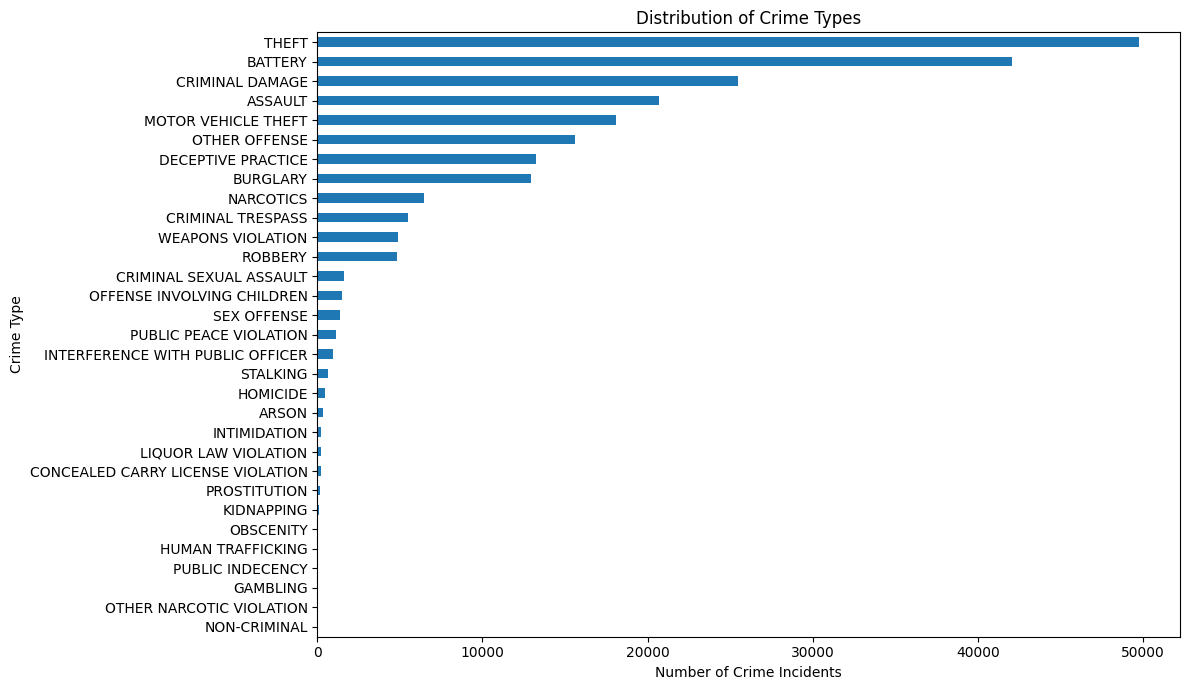

In [9]:
plt.figure(figsize=(12, 7))

crime_counts.sort_values().plot(
    kind="barh"
)

plt.title("Distribution of Crime Types")
plt.xlabel("Number of Crime Incidents")
plt.ylabel("Crime Type")
plt.tight_layout()

plt.show()

# 3.2 — Temporal EDA

#### Create temporal features

In [10]:
# Extract useful time features

df["YEAR"] = df["DATE_OF_OCCURRENCE"].dt.year
df["MONTH"] = df["DATE_OF_OCCURRENCE"].dt.month
df["MONTH_NAME"] = df["DATE_OF_OCCURRENCE"].dt.month_name()
df["DAY_OF_WEEK"] = df["DATE_OF_OCCURRENCE"].dt.day_name()
df["HOUR"] = df["DATE_OF_OCCURRENCE"].dt.hour

print("Temporal features created successfully.")

display(
    df[
        [
            "DATE_OF_OCCURRENCE",
            "YEAR",
            "MONTH",
            "MONTH_NAME",
            "DAY_OF_WEEK",
            "HOUR"
        ]
    ].head()
)

Temporal features created successfully.


,DATE_OF_OCCURRENCE,YEAR,MONTH,MONTH_NAME,DAY_OF_WEEK,HOUR
0,2025-08-24 05:03:00,2025,8,August,Sunday,5
1,2025-08-24 05:25:00,2025,8,August,Sunday,5
2,2025-08-24 05:30:00,2025,8,August,Sunday,5
3,2025-08-24 05:30:00,2025,8,August,Sunday,5
4,2025-08-24 05:32:00,2025,8,August,Sunday,5


# Check the temporal range

In [11]:
print("Minimum date:", df["DATE_OF_OCCURRENCE"].min())
print("Maximum date:", df["DATE_OF_OCCURRENCE"].max())

print("\nYears:")
print(df["YEAR"].value_counts().sort_index())

Minimum date: 2025-08-24 05:03:00
Maximum date: 2026-08-23 00:00:00

Years:
YEAR
2025     82245
2026    146350
Name: count, dtype: int64


# Monthly crime counts

In [12]:
monthly_crimes = (
    df.groupby(
        df["DATE_OF_OCCURRENCE"].dt.to_period("M")
    )
    .size()
)

monthly_crimes

DATE_OF_OCCURRENCE
2025-08     5062
2025-09    20311
2025-10    20960
2025-11    18410
2025-12    17502
2026-01    16922
2026-02    16469
2026-03    19031
2026-04    19027
2026-05    20995
2026-06    19850
2026-07    20756
2026-08    13300
Freq: M, dtype: int64

# Monthly crime graph

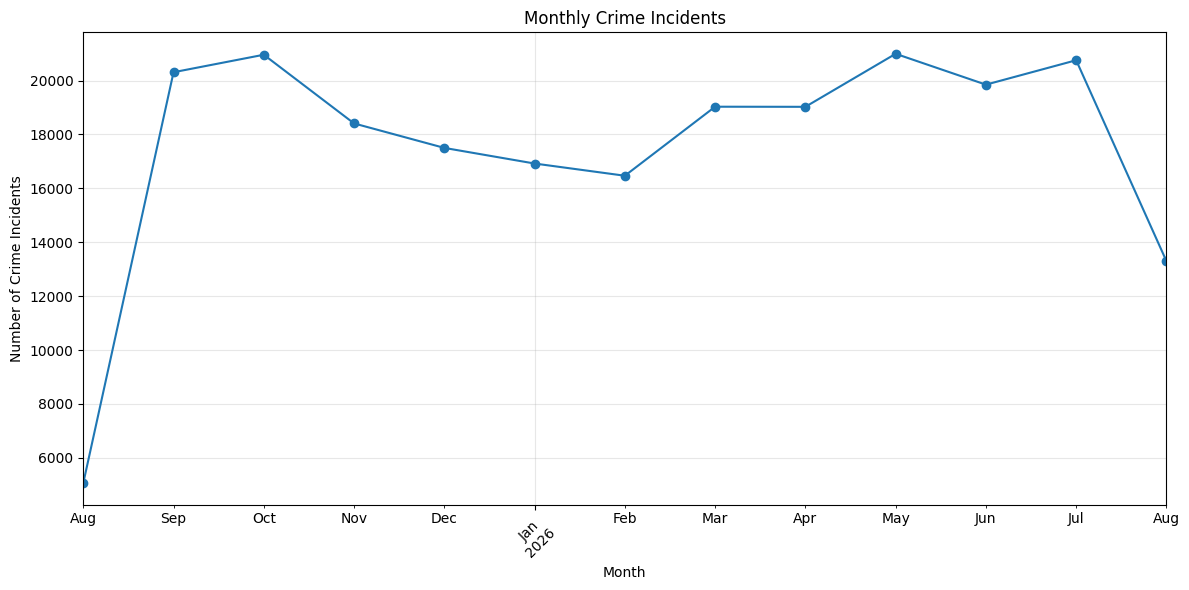

In [13]:
plt.figure(figsize=(12, 6))

monthly_crimes.plot(kind="line", marker="o")

plt.title("Monthly Crime Incidents")
plt.xlabel("Month")
plt.ylabel("Number of Crime Incidents")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

### Day of week

#### To see which days have more reported crime

In [14]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

day_counts = (
    df["DAY_OF_WEEK"]
    .value_counts()
    .reindex(day_order)
)

day_counts

DAY_OF_WEEK
Monday       32715
Tuesday      31923
Wednesday    32375
Thursday     32089
Friday       33696
Saturday     33245
Sunday       32552
Name: count, dtype: int64

# Day-of-week graph

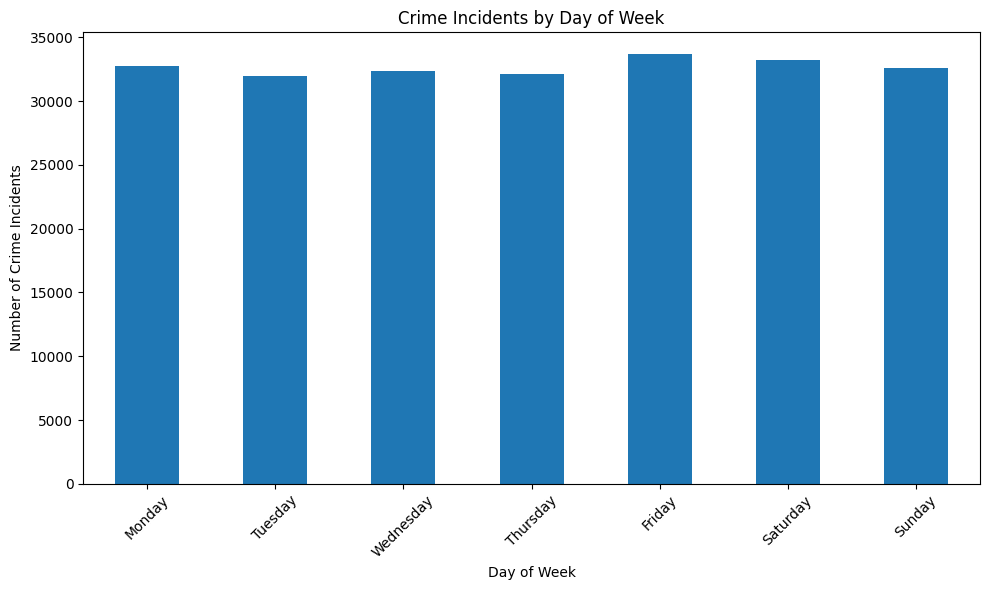

In [15]:
plt.figure(figsize=(10, 6))

day_counts.plot(kind="bar")

plt.title("Crime Incidents by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Crime Incidents")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

## Hourly crime distribution

In [16]:
hour_counts = (
    df["HOUR"]
    .value_counts()
    .sort_index()
)

hour_counts

HOUR
0     15173
1      7558
2      6788
3      6238
4      5096
5      4321
6      4823
7      5984
8      7912
9      9456
10     9988
11    10183
12    12757
13    10495
14    11191
15    12292
16    12258
17    12188
18    12231
19    11773
20    10974
21    10098
22     9884
23     8934
Name: count, dtype: int64

# Hourly crime graph

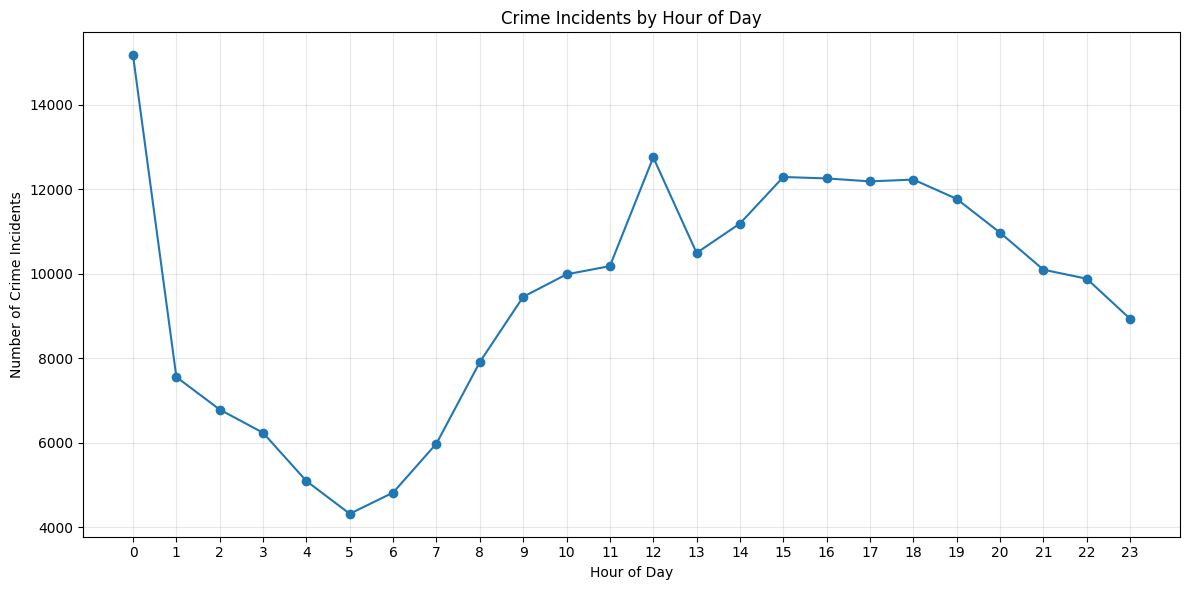

In [17]:
plt.figure(figsize=(12, 6))

hour_counts.plot(kind="line", marker="o")

plt.title("Crime Incidents by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Crime Incidents")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

# Most Common Crime hour and Day

In [19]:
most_common_hour = hour_counts.idxmax()
most_common_hour_count = hour_counts.max()

most_common_day = day_counts.idxmax()
most_common_day_count = day_counts.max()

print(
    f"Most common crime hour: {most_common_hour}:00 "
    f"({most_common_hour_count:,} incidents)"
)

print(
    f"Most common crime day: {most_common_day} "
    f"({most_common_day_count:,} incidents)"
)

Most common crime hour: 0:00 (15,173 incidents)
Most common crime day: Friday (33,696 incidents)


# 3.3 — Spatial EDA

## Crime count by police beat

In [20]:
beat_counts = (
    df["BEAT"]
    .value_counts()
    .sort_values(ascending=False)
)

print("Number of unique beats:", beat_counts.size)

display(beat_counts.head(20))

Number of unique beats: 272


BEAT
1834    2761
123     1908
1831    1730
421     1699
112     1613
1214    1587
631     1547
331     1545
222     1540
1832    1504
1232    1501
823     1496
624     1486
1224    1483
511     1443
321     1406
111     1394
612     1390
122     1359
423     1343
Name: count, dtype: int64

## Top 20 beats graph

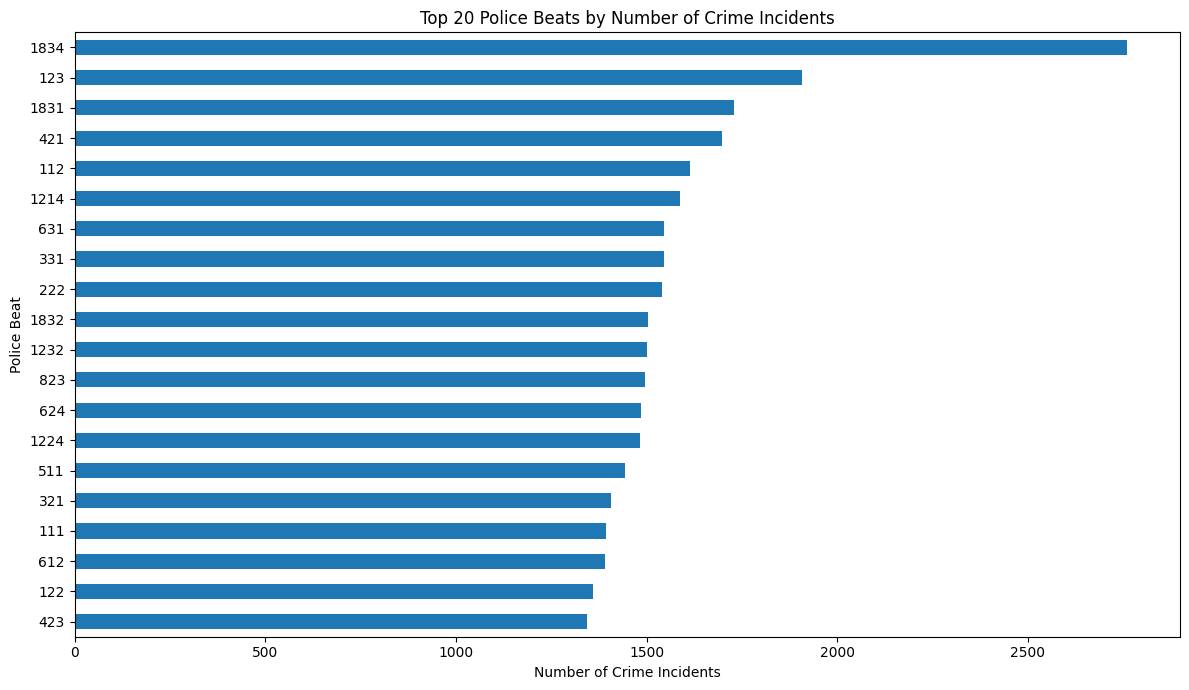

In [21]:
plt.figure(figsize=(12, 7))

beat_counts.head(20).sort_values().plot(kind="barh")

plt.title("Top 20 Police Beats by Number of Crime Incidents")
plt.xlabel("Number of Crime Incidents")
plt.ylabel("Police Beat")
plt.tight_layout()

plt.show()

## Crime count by ward

In [22]:
ward_counts = (
    df["WARD"]
    .value_counts()
    .sort_values(ascending=False)
)

print("Number of wards with crime records:", ward_counts.size)

display(ward_counts.head(20))

Number of wards with crime records: 50


WARD
27.0    10823
28.0    10204
6.0      8569
42.0     8242
20.0     7815
24.0     7810
4.0      7598
17.0     7135
9.0      6974
16.0     6865
8.0      6787
21.0     6757
7.0      6669
34.0     6546
37.0     6330
3.0      6219
5.0      6187
10.0     5030
29.0     4790
1.0      4083
Name: count, dtype: int64

# Top 20 wards graph

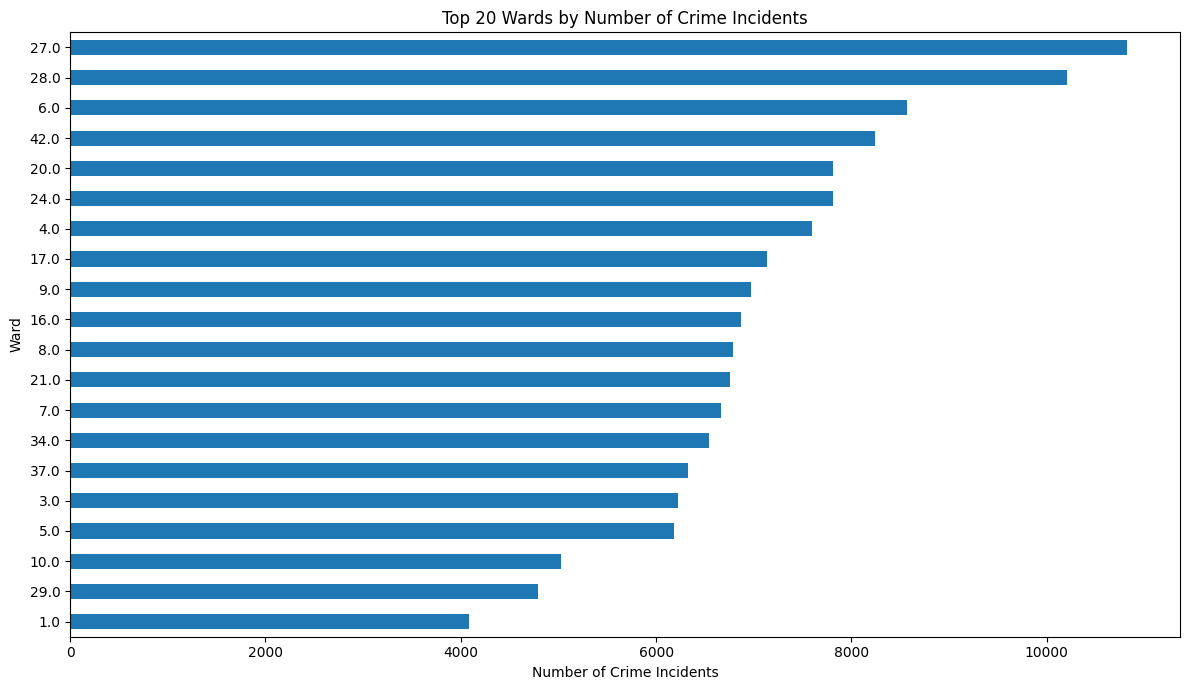

In [23]:
plt.figure(figsize=(12, 7))

ward_counts.head(20).sort_values().plot(kind="barh")

plt.title("Top 20 Wards by Number of Crime Incidents")
plt.xlabel("Number of Crime Incidents")
plt.ylabel("Ward")
plt.tight_layout()

plt.show()

## Basic spatial statistics

In [24]:
print("Latitude statistics:")
print(df["LATITUDE"].describe())

print("\nLongitude statistics:")
print(df["LONGITUDE"].describe())

Latitude statistics:
count    228595.000000
mean         41.845479
std           0.085853
min          41.644590
25%          41.771878
50%          41.863281
75%          41.907736
max          42.022548
Name: LATITUDE, dtype: float64

Longitude statistics:
count    228595.000000
mean        -87.666775
std           0.057793
min         -87.899493
25%         -87.707930
50%         -87.659942
75%         -87.626157
max         -87.524529
Name: LONGITUDE, dtype: float64


## Longitude vs Latitude scatter plot

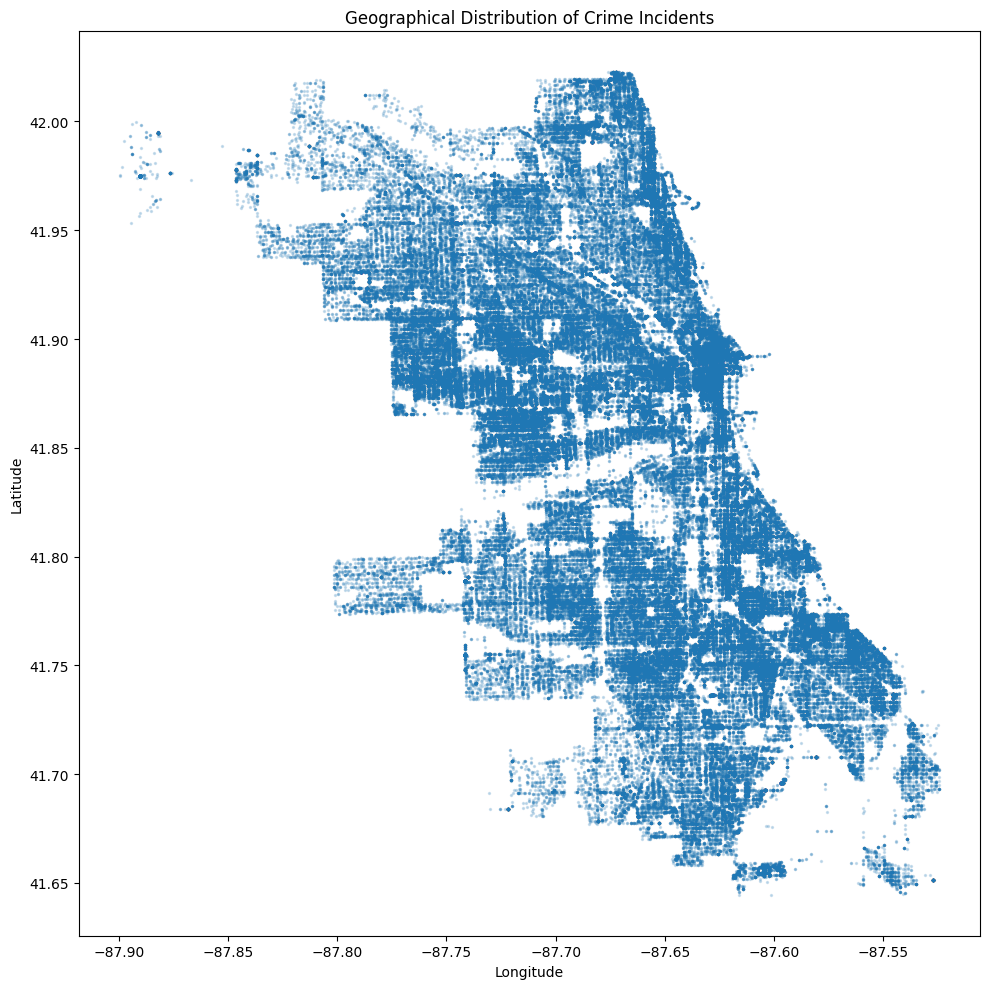

In [25]:
plt.figure(figsize=(10, 10))

plt.scatter(
    df["LONGITUDE"],
    df["LATITUDE"],
    s=2,
    alpha=0.2
)

plt.title("Geographical Distribution of Crime Incidents")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.tight_layout()
plt.show()

# Check spatial uniqueness

In [26]:
unique_coordinates = (
    df[["LATITUDE", "LONGITUDE"]]
    .drop_duplicates()
)

print("Total crime records:", len(df))
print("Unique latitude-longitude pairs:", len(unique_coordinates))
print(
    "Repeated coordinate records:",
    len(df) - len(unique_coordinates)
)

Total crime records: 228595
Unique latitude-longitude pairs: 112060
Repeated coordinate records: 116535
